## Predict Median House Value for California Houses

1. Load the California Housing dataset.
2. Split the dataset into a training set and a test set.
3. Build a pipeline for polynomial regression, with all the features.
4. Train and evaluate the model.


### Import libraries

In [38]:
# import libraries
import pandas as pd                                   # work with tables of data (DataFrames)
import numpy as np                                    # work with arrays of numbers
import matplotlib.pyplot as plt                       # draw plots
from sklearn import datasets                          # standard datasets
from sklearn.model_selection import train_test_split  # split a dataset into a training set and a test set
from sklearn.linear_model import LinearRegression     # the linear regression model
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score  # evaluation metrics
from sklearn.feature_selection import SelectKBest    # the filter method
from sklearn.feature_selection import r_regression   # score function: Pearson correlation coefficient
from sklearn.feature_selection import f_regression   # score function: F statistic (computed from the correlation)
from sklearn.feature_selection import mutual_info_regression # score function: mutual regression
from sklearn.preprocessing import PolynomialFeatures  # create polynomial features
from sklearn.preprocessing import StandardScaler      # put the features on similar scales
from sklearn.pipeline import Pipeline                 # link several steps together

### Load the California Housing dataset

In [3]:
# Load data set
feature_df, target_df = datasets.fetch_california_housing(
    return_X_y = True,   # return the features and the target separately
    as_frame = True,     # return them as a pandas DataFrame and a Series
    #scaled = False       # keep the original (raw) values
)

### Split the dataset into a training set and a test set

In [6]:
# Split the dataset into a training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    feature_df.values,   # features (all 10 features), as a NumPy array
    target_df.values,    # target, as a NumPy array
    train_size = 0.7,    # 50% for training, 50% for testing
    shuffle = True,      # no shuffling: the first half of the rows goes to the training set
    random_state = 1    # same split as solution
)

### Build a pipeline for polynomial regression

In [7]:
# Create pipeline
pipeline = Pipeline(
    [
        ('poly', PolynomialFeatures(degree = 2, include_bias = False)),
        ('scaler', StandardScaler()),
        ('mlr', LinearRegression(fit_intercept = True))
    ]
)

### Train and evaluate the model

- Fit the model on the training set.
- Make predictions on the training set and on the test set.
- Compute these metrics on both the training set and the test set: RMSE, MAE and $R^2$.
- Plot the predictions, for the training set and for the test set.

RMSE train: 0.6463088028708364
MAE train: 0.4594575884536951
R2 train: 0.6879587070059151


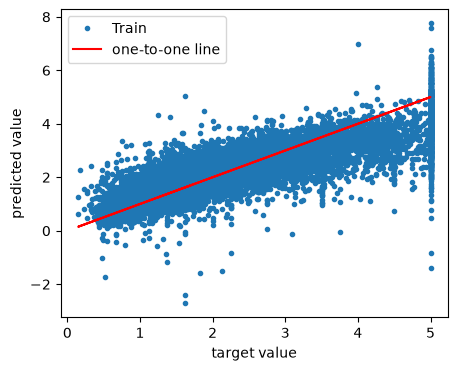

RMSE test: 0.6646203949701082
MAE test: 0.4630670403618142
R2 test: 0.6639605011311744


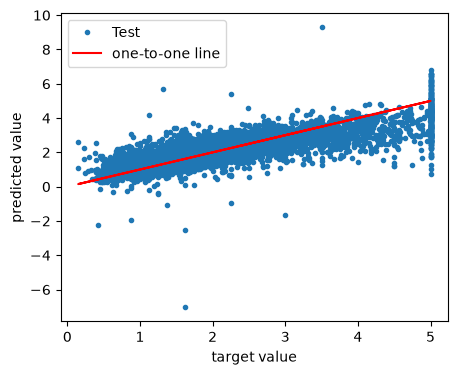

In [9]:
# fit the polynomial regression model on the training set
pipeline.fit(X_train, y_train)

# model performance on the training set
rmse_train = root_mean_squared_error(y_train, pipeline.predict(X_train))
mae_train = mean_absolute_error(y_train, pipeline.predict(X_train))
r2_train = r2_score(y_train, pipeline.predict(X_train))

print("RMSE train:", rmse_train)
print("MAE train:", mae_train)
print("R2 train:", r2_train)

# Model training graph
plt.figure(figsize = [5, 4])
plt.plot(y_train, pipeline.predict(X_train), '.', label = 'Train')
plt.plot(y_train, y_train, 'r-', label = 'one-to-one line')
plt.legend()
plt.xlabel('target value')
plt.ylabel('predicted value')
plt.show()

# make predictions on the test set
y_pred = pipeline.predict(X_test)

# model performance on the test set
rmse_test = root_mean_squared_error(y_test, y_pred)
mae_test = mean_absolute_error(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)

print("RMSE test:", rmse_test)
print("MAE test:", mae_test)
print("R2 test:", r2_test)

# Model testing graph
plt.figure(figsize = [5, 4])
plt.plot(y_test, y_pred, '.', label = 'Test')
plt.plot(y_test, y_test, 'r-', label = 'one-to-one line')
plt.legend()
plt.xlabel('target value')
plt.ylabel('predicted value')
plt.show()

### Under-fitting and over-fitting

RMSE train: 0.7227907527411359
RMSE test: 0.7277531445572312
RMSE train: 0.6463088028708364
RMSE test: 0.6646203949701082
RMSE train: 0.5847493979827195
RMSE test: 0.7315051209976843
RMSE train: 0.5581233930431787
RMSE test: 1.0413409285527715
RMSE train: 0.5353014658951486
RMSE test: 7.40688819239111
RMSE train: 0.5263483004804259
RMSE test: 7.500572632864898


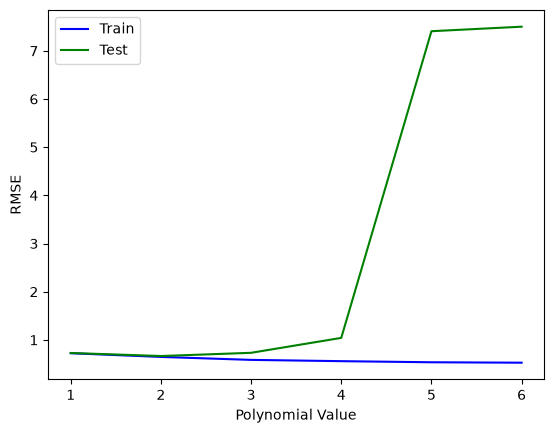

In [ ]:
# Create lists for values for RMSE
degree_range = [1, 2, 3, 4, 5, 6]
rmse_train_list = []
rmse_test_list = []

# Cycle through the degree range and build list for RMSE values both on train and test sets
for i in degree_range:
    pipeline = Pipeline(
        [
            ('poly', PolynomialFeatures(degree = i, include_bias = False)),
            ('scaler', StandardScaler()),
            ('mlr', LinearRegression(fit_intercept = True))
        ]
    )

    # fit the polynomial regression model on the training set
    pipeline.fit(X_train, y_train)

    # obtain values for RMSE on train and test data sets
    rmse_train = root_mean_squared_error(y_train, pipeline.predict(X_train))
    rmse_test = root_mean_squared_error(y_test, pipeline.predict(X_test))
    print("RMSE train:", rmse_train)
    print("RMSE test:", rmse_test)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)

# Plot the test and train plots against each other
plt.figure()
plt.plot(degree_range, rmse_train_list, c = 'blue', label = 'Train')
plt.plot(degree_range, rmse_test_list, c = 'green', label = 'Test')
plt.xlabel('Polynomial Value')
plt.ylabel('RMSE')
plt.legend()
plt.show()

The model appears to overfit after the 3rd degree polynomial is used to test the data set.

### Add feature selection to the pipeline

RMSE train: 0.7227907527411359
RMSE test: 0.7277531445572312
RMSE train: 0.7213096252998179
RMSE test: 0.7218040427567006
RMSE train: 0.7295144159170277
RMSE test: 0.7303971959963248
RMSE train: 0.7340855838700301
RMSE test: 0.7407985295912035
RMSE train: 0.7396002482060757
RMSE test: 0.7445480314444514
RMSE train: 0.7386564873974878
RMSE test: 0.7432051169555828


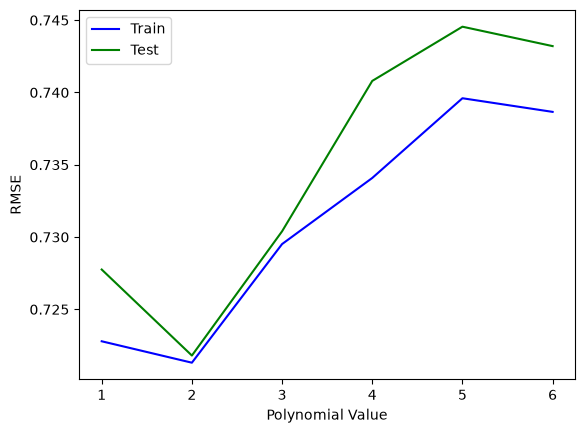

In [ ]:
# Create lists for values for RMSE
degree_range = [1, 2, 3, 4, 5, 6]
rmse_train_list = []
rmse_test_list = []

# Cycle through the degree range and build list for RMSE values both on train and test sets
for i in degree_range:
    pipeline = Pipeline(
        [
            ('poly', PolynomialFeatures(degree = i, include_bias = False)),
            ('scaler', StandardScaler()),
            ('ftest', SelectKBest(score_func = f_regression, k = 8)),
            ('mlr', LinearRegression(fit_intercept = True))
        ]
    )

    # fit the polynomial regression model on the training set
    pipeline.fit(X_train, y_train)

    # obtain values for RMSE on train and test data sets
    rmse_train = root_mean_squared_error(y_train, pipeline.predict(X_train))
    rmse_test = root_mean_squared_error(y_test, pipeline.predict(X_test))
    print("RMSE train:", rmse_train)
    print("RMSE test:", rmse_test)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)

# Plot the test and train plots against each other
plt.figure()
plt.plot(degree_range, rmse_train_list, c = 'blue', label = 'Train')
plt.plot(degree_range, rmse_test_list, c = 'green', label = 'Test')
plt.xlabel('Polynomial Value')
plt.ylabel('RMSE')
plt.legend()
plt.show()

We can observe that the RMSE across every polynomial value is far less than the previous section which did not have the feature selection.